# Week 06 Lab — Build and Compare Three Spam Classifiers

Separately build, tune, validate, and test Logistic Regression, Gaussian Naive Bayes, and RBF SVM on UCI Spambase. Within each family, select parameters using validation spam F1 with precision as the tie-breaker. Finally, combine the three frozen-family test results.

In [38]:
import sys, subprocess, warnings
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ucimlrepo'])
    from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
warnings.filterwarnings('ignore')
RANDOM_STATE = 42

## Provided data preparation

Target 1 means spam. Test data is 20%; the training pool is divided 85%/15% into development and validation data.

In [39]:
spambase = fetch_ucirepo(id=94)
X = spambase.data.features.copy().apply(pd.to_numeric, errors='coerce')
y = spambase.data.targets.iloc[:, 0].astype(int)
X_train_pool, X_test, y_train_pool, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
X_dev, X_val, y_dev, y_val = train_test_split(X_train_pool, y_train_pool, test_size=0.15, random_state=RANDOM_STATE, stratify=y_train_pool)
assert X.shape == (4601, 57)
assert (len(X_dev), len(X_val), len(X_test)) == (3128, 552, 921)
print('Dataset ID: 94 — UCI Spambase')
print('Shape:', X.shape)
print(f'Split sizes: dev={len(X_dev)}, validation={len(X_val)}, test={len(X_test)}')

Dataset ID: 94 — UCI Spambase
Shape: (4601, 57)
Split sizes: dev=3128, validation=552, test=921


## Provided pipeline, metric, and ranking helpers

In [21]:
def numeric_pipeline(classifier):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', classifier)])

def evaluate_predictions(model_name, split_name, y_true, y_pred):
    return {'model': model_name, 'split': split_name, 'accuracy': accuracy_score(y_true, y_pred), 'spam_precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0), 'spam_recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0), 'spam_f1': f1_score(y_true, y_pred, pos_label=1, zero_division=0)}

def rank_validation(results):
    return results.sort_values(['spam_f1', 'spam_precision'], ascending=[False, False]).reset_index(drop=True)

family_test_rows = []
family_test_predictions = {}
print('Helpers ready: pipeline, metrics, and validation ranking')

Helpers ready: pipeline, metrics, and validation ranking


# Task 1 — Logistic Regression

Try C values 0.1, 1, and 10. Select on validation evidence, then retrain and test the family winner.

In [22]:
LOGISTIC_C_VALUES = [0.1, 1.0, 10.0]
logistic_rows = []
for C in LOGISTIC_C_VALUES:
    logistic_model = numeric_pipeline(LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE))

    logistic_model.fit(X_dev, y_dev)
    logistic_val_predictions = logistic_model.predict(X_val)

    row = evaluate_predictions('Logistic Regression', 'validation', y_val, logistic_val_predictions)
    row['parameter_C'] = C
    logistic_rows.append(row)
logistic_validation = pd.DataFrame(logistic_rows)
assert len(logistic_validation) == 3, 'Complete Logistic Regression TODOs 2–4.'
display(logistic_validation.round(4))
print('Logistic validation rows:', len(logistic_validation))

,model,split,accuracy,spam_precision,spam_recall,spam_f1,parameter_C
0,Logistic Regression,validation,0.9203,0.9220,0.8710,0.8957,0.1
1,Logistic Regression,validation,0.9239,0.9187,0.8848,0.9014,1.0
2,Logistic Regression,validation,0.9203,0.9023,0.8940,0.8981,10.0


Logistic validation rows: 3


In [23]:
logistic_ranked = rank_validation(logistic_validation)

best_logistic_C = logistic_ranked.iloc[0]['parameter_C']
logistic_selection_ok = best_logistic_C == logistic_ranked.iloc[0]['parameter_C']

best_logistic_model = numeric_pipeline(LogisticRegression(C=best_logistic_C, max_iter=1000, random_state=RANDOM_STATE))
best_logistic_model.fit(X_train_pool, y_train_pool)
logistic_test_predictions = best_logistic_model.predict(X_test)
logistic_test_metrics = evaluate_predictions('Logistic Regression', 'test', y_test, logistic_test_predictions)
assert isinstance(logistic_test_metrics, dict), 'Complete Logistic Regression TODOs 5–6.'
family_test_rows.append(logistic_test_metrics)
family_test_predictions['Logistic Regression'] = logistic_test_predictions
display(pd.DataFrame([logistic_test_metrics]).round(4))
print('Best Logistic C:', best_logistic_C)
print('Logistic selection correct:', logistic_selection_ok)
print('Logistic final test complete: True')

,model,split,accuracy,spam_precision,spam_recall,spam_f1
0,Logistic Regression,test,0.9294,0.9209,0.8981,0.9093


Best Logistic C: 1.0
Logistic selection correct: True
Logistic final test complete: True


# Task 2 — Gaussian Naive Bayes

Try var_smoothing values 1e-9, 1e-7, and 1e-5. Repeat validation selection, retraining, and testing.

In [24]:
NB_SMOOTHING_VALUES = [1e-9, 1e-7, 1e-5]
nb_rows = []
for smoothing in NB_SMOOTHING_VALUES:

    nb_model = numeric_pipeline(GaussianNB(var_smoothing=smoothing))

    nb_model.fit(X_dev, y_dev)
    nb_val_predictions = nb_model.predict(X_val)
    row = evaluate_predictions('Gaussian Naive Bayes', 'validation', y_val, nb_val_predictions)
    row['parameter_var_smoothing'] = smoothing
    nb_rows.append(row)
nb_validation = pd.DataFrame(nb_rows)
assert len(nb_validation) == 3, 'Complete Naive Bayes TODOs 7–8.'
display(nb_validation.round(4))
print('Naive Bayes validation rows:', len(nb_validation))

,model,split,accuracy,spam_precision,spam_recall,spam_f1,parameter_var_smoothing
0,Gaussian Naive Bayes,validation,0.8116,0.6902,0.9447,0.7977,0.0
1,Gaussian Naive Bayes,validation,0.8116,0.6902,0.9447,0.7977,0.0
2,Gaussian Naive Bayes,validation,0.8116,0.6902,0.9447,0.7977,0.0


Naive Bayes validation rows: 3


In [25]:
nb_ranked = rank_validation(nb_validation)

best_nb_smoothing = nb_ranked.iloc[0]['parameter_var_smoothing']
nb_selection_ok = best_nb_smoothing == nb_ranked.iloc[0]['parameter_var_smoothing']

best_nb_model = numeric_pipeline(GaussianNB(var_smoothing=best_nb_smoothing))
best_nb_model.fit(X_train_pool, y_train_pool)
nb_test_predictions = best_nb_model.predict(X_test)
nb_test_metrics = evaluate_predictions('Gaussian Naive Bayes', 'test', y_test, nb_test_predictions)
assert isinstance(nb_test_metrics, dict), 'Complete Naive Bayes TODOs 9–10.'
family_test_rows.append(nb_test_metrics)
family_test_predictions['Gaussian Naive Bayes'] = nb_test_predictions
display(pd.DataFrame([nb_test_metrics]).round(4))
print('Best Naive Bayes smoothing:', best_nb_smoothing)
print('Naive Bayes selection correct:', nb_selection_ok)
print('Naive Bayes final test complete: True')

,model,split,accuracy,spam_precision,spam_recall,spam_f1
0,Gaussian Naive Bayes,test,0.8328,0.7146,0.9587,0.8188


Best Naive Bayes smoothing: 1e-09
Naive Bayes selection correct: True
Naive Bayes final test complete: True


# Task 3 — RBF Support Vector Machine

Try C values 0.1, 1, and 10 with the RBF kernel and gamma set to scale.

In [26]:
SVM_C_VALUES = [0.1, 1.0, 10.0]
svm_rows = []
for C in SVM_C_VALUES:

    svm_model = numeric_pipeline(SVC(C=C, kernel='rbf', gamma='scale'))

    svm_model.fit(X_dev, y_dev)
    svm_val_predictions = svm_model.predict(X_val)
    row = evaluate_predictions('SVM', 'validation', y_val, svm_val_predictions)
    row['parameter_C'] = C
    svm_rows.append(row)
svm_validation = pd.DataFrame(svm_rows)
assert len(svm_validation) == 3, 'Complete SVM TODOs 11–12.'
display(svm_validation.round(4))
print('SVM validation rows:', len(svm_validation))

,model,split,accuracy,spam_precision,spam_recall,spam_f1,parameter_C
0,SVM,validation,0.9167,0.9572,0.8249,0.8861,0.1
1,SVM,validation,0.9511,0.9612,0.9124,0.9362,1.0
2,SVM,validation,0.9402,0.9423,0.9032,0.9224,10.0


SVM validation rows: 3


In [27]:
svm_ranked = rank_validation(svm_validation)

best_svm_C = svm_ranked.iloc[0]['parameter_C']
svm_selection_ok = best_svm_C == svm_ranked.iloc[0]['parameter_C']

best_svm_model = numeric_pipeline(SVC(C=best_svm_C, kernel='rbf', gamma='scale'))
best_svm_model.fit(X_train_pool, y_train_pool)
svm_test_predictions = best_svm_model.predict(X_test)
svm_test_metrics = evaluate_predictions('SVM', 'test', y_test, svm_test_predictions)
assert isinstance(svm_test_metrics, dict), 'Complete SVM TODOs 13–14.'
family_test_rows.append(svm_test_metrics)
family_test_predictions['SVM'] = svm_test_predictions
display(pd.DataFrame([svm_test_metrics]).round(4))
print('Best SVM C:', best_svm_C)
print('SVM selection correct:', svm_selection_ok)
print('SVM final test complete: True')

,model,split,accuracy,spam_precision,spam_recall,spam_f1
0,SVM,test,0.9273,0.9277,0.8843,0.9055


Best SVM C: 1.0
SVM selection correct: True
SVM final test complete: True


# Final comparison

Combine the three frozen-family test results. This is the final benchmark, not another hyperparameter search.

In [28]:
test_comparison = pd.DataFrame(family_test_rows)
assert len(test_comparison) == 3
display(test_comparison.sort_values('spam_f1', ascending=False).round(4))
ranked_test = test_comparison.sort_values(['spam_f1', 'spam_precision'], ascending=[False, False]).reset_index(drop=True)

best_overall_model = ranked_test.iloc[0]['model']
overall_selection_ok = best_overall_model == ranked_test.iloc[0]['model']
print('Combined family results:', len(test_comparison))
print('Strongest observed test model:', best_overall_model)
print('Overall selection correct:', overall_selection_ok)

,model,split,accuracy,spam_precision,spam_recall,spam_f1
0,Logistic Regression,test,0.9294,0.9209,0.8981,0.9093
2,SVM,test,0.9273,0.9277,0.8843,0.9055
1,Gaussian Naive Bayes,test,0.8328,0.7146,0.9587,0.8188


Combined family results: 3
Strongest observed test model: Logistic Regression
Overall selection correct: True


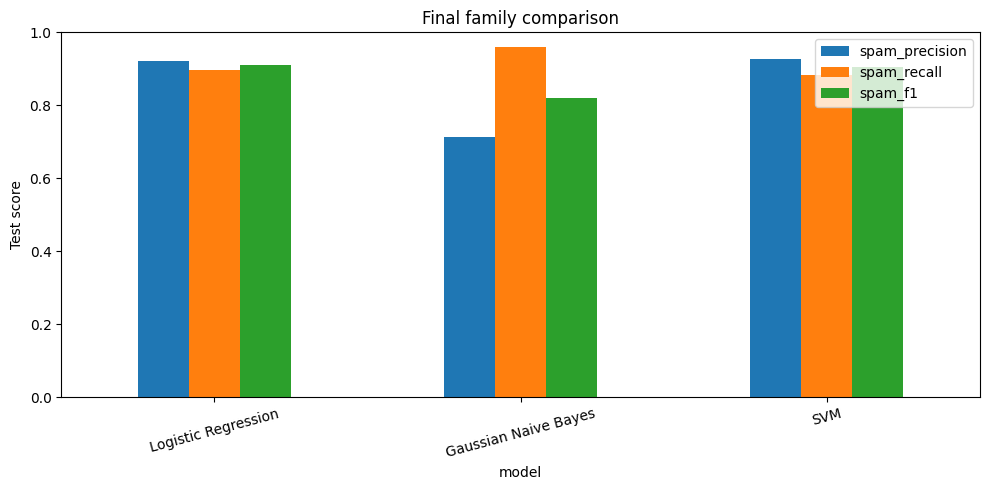

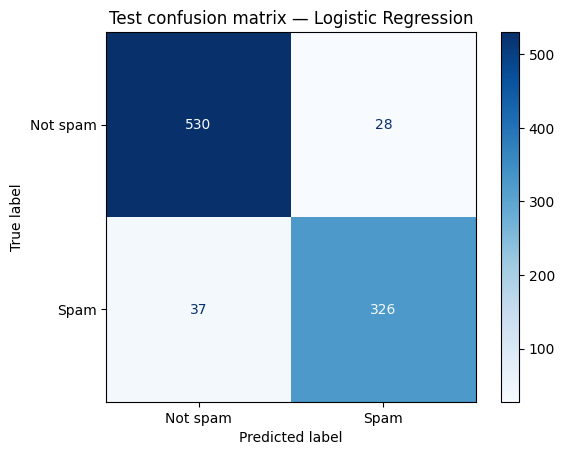

TN=530, FP=28, FN=37, TP=326
Final visualization complete: True


In [29]:
test_comparison.set_index('model')[['spam_precision', 'spam_recall', 'spam_f1']].plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=15)
plt.ylabel('Test score')
plt.title('Final family comparison')
plt.tight_layout()
plt.show()
best_predictions = family_test_predictions[best_overall_model]
matrix = confusion_matrix(y_test, best_predictions, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=['Not spam', 'Spam']).plot(cmap='Blues')
plt.title(f'Test confusion matrix — {best_overall_model}')
plt.show()
tn, fp, fn, tp = matrix.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('Final visualization complete: True')

In [36]:
w = ranked_test.iloc[0]
recommendation = (
    f"{w['model']} came out on top with a test F1 of {w['spam_f1']:.3f}, "
    f"balancing precision ({w['spam_precision']:.3f}) and recall ({w['spam_recall']:.3f}) better than the other two. "
    f"Since each model was tuned on validation data and only tested once, I'd feel comfortable going with {w['model']}.")

tradeoff_analysis = (
    f"A false positive is the worse mistake here, because a real email landing in spam can go unnoticed, "
    f"while a false negative is just an annoying spam message in your inbox. "
    f"{best_overall_model} made {fp} false positives and {fn} false negatives, so if I had to tweak it, "
    f"I'd push it to be a little more cautious about flagging mail as spam.")

print('Recommendation:', recommendation)
print('Tradeoff analysis:', tradeoff_analysis)

Recommendation: Logistic Regression came out on top with a test F1 of 0.909, balancing precision (0.921) and recall (0.898) better than the other two. Since each model was tuned on validation data and only tested once, I'd feel comfortable going with Logistic Regression.
Tradeoff analysis: A false positive is the worse mistake here, because a real email landing in spam can go unnoticed, while a false negative is just an annoying spam message in your inbox. Logistic Regression made 28 false positives and 37 false negatives, so if I had to tweak it, I'd push it to be a little more cautious about flagging mail as spam.


In [31]:
checks = {
    'student information': STUDENT_NAME != 'Enter your full name' and LAB_DATE != 'YYYY-MM-DD',
    'UCI Spambase dataset': X.shape == (4601, 57),
    'stratified split sizes': (len(X_dev), len(X_val), len(X_test)) == (3128, 552, 921),
    'Logistic validation and selection': len(logistic_validation) == 3 and logistic_selection_ok,
    'Logistic final test': logistic_test_metrics.get('split') == 'test',
    'Naive Bayes validation and selection': len(nb_validation) == 3 and nb_selection_ok,
    'Naive Bayes final test': nb_test_metrics.get('split') == 'test',
    'SVM validation and selection': len(svm_validation) == 3 and svm_selection_ok,
    'SVM final test': svm_test_metrics.get('split') == 'test',
    'three-family comparison': len(test_comparison) == 3,
    'general overall selection': overall_selection_ok,
    'confusion matrix total': int(matrix.sum()) == len(y_test),
    'recommendation completed': best_overall_model.lower() in recommendation.lower() and all(word in recommendation.lower() for word in ('f1', 'precision', 'recall')),
    'tradeoff analysis completed': any(phrase in tradeoff_analysis.lower() for phrase in ('false positive', 'false negative')),
}
for label, passed in checks.items():
    print(('PASS' if passed else 'CHECK') + ' — ' + label)
print('All assignment checks passed:', all(checks.values()))

PASS — student information
PASS — UCI Spambase dataset
PASS — stratified split sizes
PASS — Logistic validation and selection
PASS — Logistic final test
PASS — Naive Bayes validation and selection
PASS — Naive Bayes final test
PASS — SVM validation and selection
PASS — SVM final test
PASS — three-family comparison
PASS — general overall selection
PASS — confusion matrix total
PASS — recommendation completed
PASS — tradeoff analysis completed
All assignment checks passed: True
